# 제조AI실제 13주차 · TSB-AD 기초 사용 가이드: LSTMAD

## 1) 개요

**사용 데이터:** NAB(Numenta Anomaly Benchmark)
- NAB(Numenta Anomaly Benchmark)는 시간에 따라 변하는 모니터링 지표와
정답 이상 구간으로 시계열 이상감지를 평가하는 벤치마크임
- 이번 실습은 TSB-AD에 동봉된 **AWS 서버 장애 관련 단변량 모니터링 시계열** 한 개를 사용
- 센서값에 해당하는 `Data` 한 열과 정상 0·이상 1의 `Label`이 있으며, 총 **4,031개 관측**이 있음

**분석 방법:** **과거 32개 값으로 다음 1개 값을 예측**하는 예측 기반 모델
- 정상 패턴을 학습한 LSTMAD가 실제 관측을 잘 예측하지 못하면 평균제곱 예측오차(MSE)가 커지며 이를 이상점수로 사용함
- 원본 파형과 실제 모델 입력을 시각화한 뒤 다음 순서로 분석함

    1. 처음 정상 1,007개 중 앞 **805개를 모델 학습·내부 검증**, 뒤 **202개를 임계값 보정**에 사용
    2. 공식 `LSTMAD(...)` → `fit()` → `decision_function()`으로 학습과 점수 계산을 실행
    3. 정상 보정 점수의 **99% 분위수**를 넘으면 이상으로 예측
    4. 이후 시험 관측의 **정확도·F1-Score·AUROC·NAB Score**를 계산하고, 항상 정상이라고 예측한 기준선과 비교

### 실행 준비

- Python 3.12의 Jupyter 커널을 선택
- 필요한 패키지가 없다면 아래 명령을 새 코드 셀에서 한 번 실행하고 커널을 재시작함

```python
%pip install torch==2.5.1 --index-url https://download.pytorch.org/whl/cpu
%pip install numpy==1.26.4 pandas==2.2.3 matplotlib==3.9.4 scikit-learn==1.6.1 requests==2.32.3 torchinfo==1.8.0 tqdm==4.67.1
```

- 환경이 준비되어 있으면 Step 1부터 **Run All**을 실행함

### Step 1: 공식 TSB-AD 소스 다운로드

In [1]:
from pathlib import Path, PurePosixPath
import io
import sys
import zipfile
import requests

TSB_SHA = "303dffbfc11612995b17b06633f8c9d0ea0e38e5"
LAB_DIR = Path.cwd() / "lab13" if (Path.cwd() / "lab13").is_dir() else Path.cwd()
TSB_SOURCE_ROOT = LAB_DIR / ".cache" / f"TSB-AD-{TSB_SHA}"

if not (TSB_SOURCE_ROOT / "TSB_AD/models/LSTMAD.py").is_file():
    response = requests.get(
        f"https://api.github.com/repos/thedatumorg/TSB-AD/zipball/{TSB_SHA}",
        timeout=(15, 90),
    )
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        prefix = archive.namelist()[0].split("/")[0]
        for item in archive.infolist():
            relative = PurePosixPath(item.filename).relative_to(prefix)
            if item.is_dir() or not relative.parts:
                continue
            target = TSB_SOURCE_ROOT.joinpath(*relative.parts)
            assert target.resolve().is_relative_to(TSB_SOURCE_ROOT.resolve())
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(archive.read(item))

sys.path.insert(0, str(TSB_SOURCE_ROOT))
print("TSB-AD source:", TSB_SOURCE_ROOT)

TSB-AD source: /home/chohi/PythonProjectLLM/AI_EDU/13w/.cache/TSB-AD-303dffbfc11612995b17b06633f8c9d0ea0e38e5


- `TSB_SHA`: 수업에서 사용하는 공식 소스 버전
- `requests.get()`, `ZipFile`: 공식 소스와 동봉 예제를 `.cache/`에 다운로드함. 이미 있으면 재사용.
- `sys.path`: 이 소스에서 TSB-AD를 불러오도록 설정

## 2) 데이터 셋

- TSB-AD-U의 `001_NAB_id_1_Facility_tr_1007_1st_2014.csv`를 사용
- 한 행은 한 시점이며 입력 열 `Data`와 정답 열 `Label`로 구성됨
- 파일명의 `tr_1007`은 정상 학습 후보 구간의 길이를 나타냄

- 여기서는 전체 파형으로 데이터 범위를 확인한 뒤, 정상 구간과 정답 이상 구간의 대표 파형을 확대하여 확인함

### Step 2: 라이브러리 불러오기와 NAB 데이터 읽기

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from TSB_AD.models.LSTMAD import LSTMAD
from TSB_AD.utils.dataset import ForecastDataset

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)
csv_path = TSB_SOURCE_ROOT / "Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv"
frame = pd.read_csv(csv_path)
NORMAL_END = 1007
print("Rows / columns:", frame.shape)
display(frame.head())

Rows / columns: (4031, 2)


,Data,Label
0,47.606,0
1,42.580,0
2,46.030,0
3,44.992,0
4,45.238,0


- `LSTMAD`: 예측기반 이상감지 모델을 불러오기
- `ForecastDataset`: 공식 모델의 표준화·윈도 변환 결과를 확인하기 위한 클래스
- `pd.read_csv()`, `frame.head()`: 센서와 정답 열을 읽고 실제 샘플을 확인
- 난수 시드를 42로 고정하고, 작은 예제를 위해 CPU 스레드 수를 2로 설정

### Step 3: 원본 시계열과 정상·이상 대표 샘플 시각화

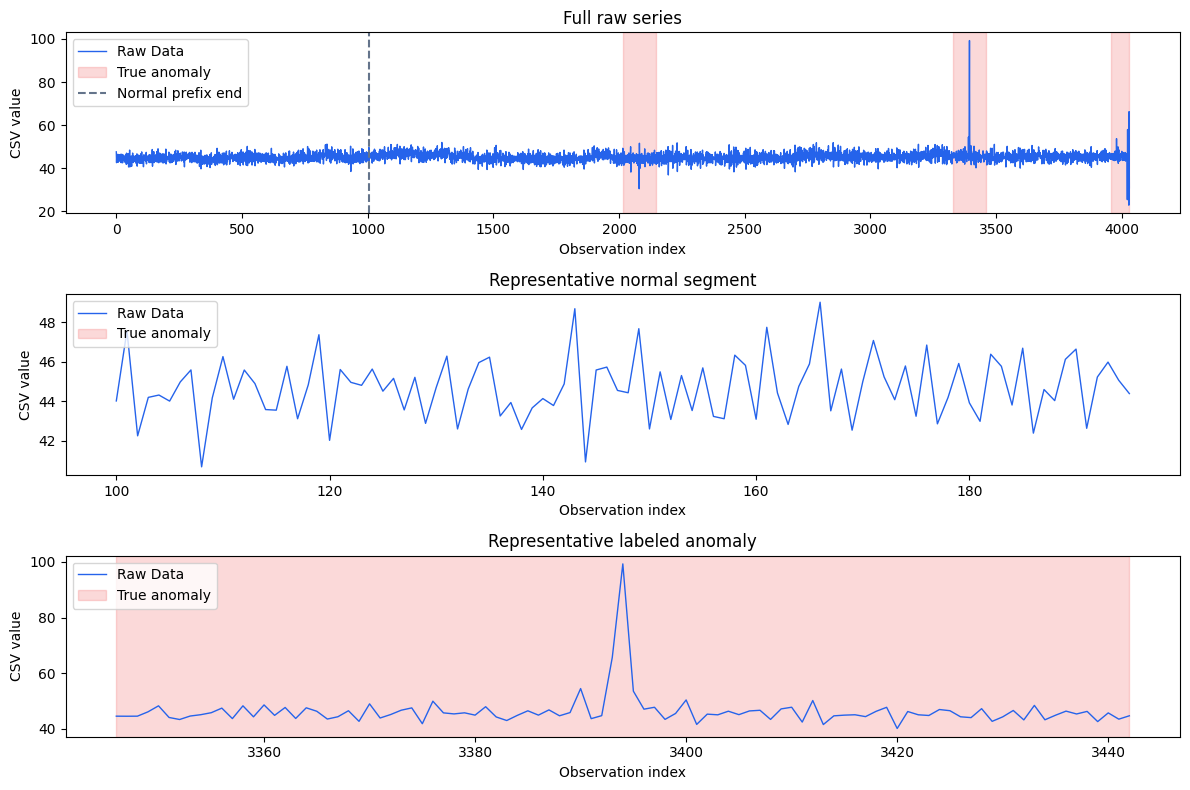

In [4]:
anomaly_center = int(frame.loc[frame["Label"] == 1, "Data"].idxmax())
regions = [(0, len(frame), "Full raw series"),
           (100, 196, "Representative normal segment"),
           (anomaly_center - 48, anomaly_center + 49, "Representative labeled anomaly")]
raw_fig, axes = plt.subplots(3, 1, figsize=(12, 8))
for ax, (start, end, title) in zip(axes, regions):
    part = frame.iloc[max(0, start):min(len(frame), end)]
    ax.plot(part.index, part["Data"], lw=1, color="#2563eb", label="Raw Data")
    ax.fill_between(part.index, 0, 1, where=part["Label"] == 1,
                    transform=ax.get_xaxis_transform(), color="#ef4444", alpha=0.2,
                    label="True anomaly")
    ax.set(title=title, xlabel="Observation index", ylabel="CSV value")
    ax.legend(loc="upper left")
axes[0].axvline(NORMAL_END, color="#64748b", ls="--", label="Normal prefix end")
axes[0].legend(loc="upper left")
raw_fig.tight_layout()
plt.show()

- 첫 그림은 전체 4,031개 관측. 점선은 처음 정상 1,007개 관측의 끝을 나타냄
- 두 번째 그림은 정상 구간의 연속 96개 관측임. 평상시 수준과 작은 변동을 확인
- 세 번째 그림은 정답 이상 중 센서값이 가장 큰 시점 주변임. 급격한 변화의 형상을 살펴봄
- 붉은 배경은 `Label=1`인 정답 구간임.

## 3) 전처리

- 센서와 정답을 분리하고 시간순으로 모델 학습용·정상 보정용·시험용 데이터를 나눔
- 정상 1,007개 중 앞 805개를 `fit()`에 전달하고,
나머지 202개는 학습 후 경보 임계값을 정하는 데 사용함
- `fit()`은 전달받은 805개를 다시 **실제 학습 644개·내부 검증 161개**로 나눔


- 이 구현은 학습·검증·보정·시험 배열을
**각 배열의 평균·표준편차로 따로 표준화**함

### Step 4: 정상 학습·보정·시험 구간 분리

In [5]:
X = frame[["Data"]].to_numpy(dtype=np.float32)
labels = frame["Label"].to_numpy()
assert np.isfinite(X).all() and np.isin(labels, [0, 1]).all()
y = labels.astype(int)
assert (y[:NORMAL_END] == 0).all()
FIT_END = int(NORMAL_END * 0.8)
train_x, calib_x = X[:FIT_END], X[FIT_END:NORMAL_END]
test_x, test_y = X[NORMAL_END:], y[NORMAL_END:]
WINDOW_SIZE, PRED_LEN, VALIDATION_SIZE = 32, 1, 0.2
print("Model fit / normal calibration / test:", train_x.shape, calib_x.shape, test_x.shape)

Model fit / normal calibration / test: (805, 1) (202, 1) (3024, 1)


- `X`: `(시점 수, 센서 수)`인 2차원 배열. 단변량도 센서 차원 1을 유지함
- `FIT_END=805`: 앞 805개는 모델 학습·내부 검증에, 뒤 정상 202개는 임계값 보정에 사용
- `test_x`, `test_y`: 이후 3,024개 센서 관측과 정답. 시험 정답은 평가 단계에서 사용함
- `WINDOW_SIZE=32`, `PRED_LEN=1`: 과거 32개를 입력으로 다음 1개를 예측

### Step 5: 전처리 전후의 실제 학습 샘플 형상 비교

All input / target shapes: (612, 32, 1) (612, 1, 1)
One input / target shape: (32, 1) (1, 1)


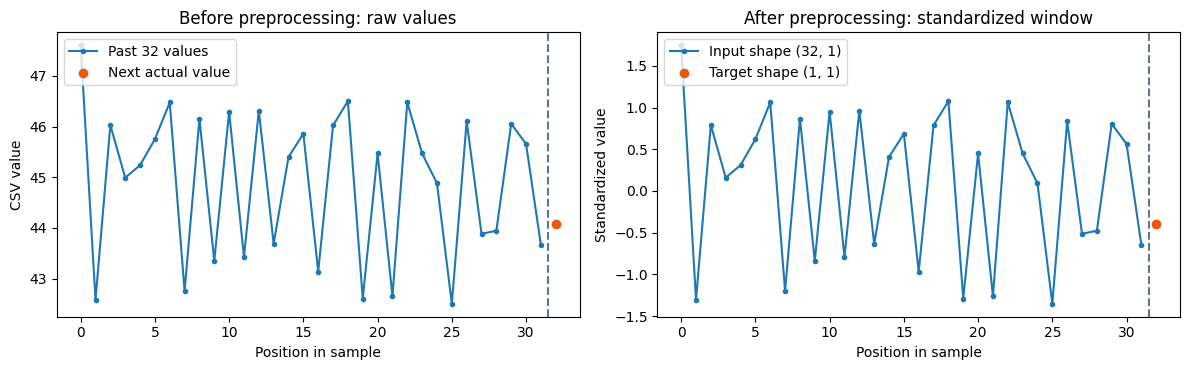

In [6]:
internal_end = int((1 - VALIDATION_SIZE) * len(train_x))
internal_train = train_x[:internal_end]
preview = ForecastDataset(internal_train, window_size=WINDOW_SIZE, pred_len=PRED_LEN)
sample_input, sample_target = preview[0]
print("All input / target shapes:", tuple(preview.samples.shape), tuple(preview.targets.shape))
print("One input / target shape:", tuple(sample_input.shape), tuple(sample_target.shape))

sample_fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(np.arange(WINDOW_SIZE), internal_train[:WINDOW_SIZE, 0], "o-", ms=3,
             label="Past 32 values")
axes[0].scatter(WINDOW_SIZE, internal_train[WINDOW_SIZE, 0], color="#ea580c",
                label="Next actual value", zorder=3)
axes[1].plot(np.arange(WINDOW_SIZE), sample_input[:, 0], "o-", ms=3,
             label="Input shape (32, 1)")
axes[1].scatter(WINDOW_SIZE, sample_target[0, 0], color="#ea580c",
                label="Target shape (1, 1)", zorder=3)
for ax in axes:
    ax.axvline(WINDOW_SIZE - 0.5, color="#64748b", ls="--")
    ax.set(xlabel="Position in sample")
    ax.legend(loc="upper left")
axes[0].set(title="Before preprocessing: raw values", ylabel="CSV value")
axes[1].set(title="After preprocessing: standardized window", ylabel="Standardized value")
sample_fig.tight_layout()
plt.show()

- `internal_train`: `fit()` 내부에서 가중치 학습에 사용하는 앞 644개 관측과 같은 구간
- `ForecastDataset`: 학습데이터 644개 전체의 평균·표준편차로 표준화하고, 입력 32개·표적 1개씩 이동 윈도 생성
- 총 입력 형상은 **`(612, 32, 1)`**, 표적 형상은 **`(612, 1, 1)`**임. 첫 차원은 샘플 수를 의미.
- 시각화 차트의 왼쪽은 원본 값, 오른쪽은 실제 모델에 들어가는 정규화된 첫 샘플임. 파란 점 32개가 입력이며 주황 점은 **다음 실제값·학습 표적**임
- 이 셀은 내부 전처리 확인용임. `fit()`에는 `preview`가 아니라 원래 2차원 `train_x`를 전달함

## 4) 모델개발

### 4-1) 모델구조선정

- **과거 32개 관측 → LSTM → 다음 1개 관측 예측**으로 모델 구조를 구성함
- 입력 구간 다음 실제값과 예측값의 MSE가 크면 이상 가능성이 높은 것으로 해석

### Step 6: LSTMAD 모델 생성

In [8]:
import numpy as np
np.Inf = np.inf

model = LSTMAD(
    window_size=WINDOW_SIZE,
    pred_len=PRED_LEN,
    feats=train_x.shape[1],
    epochs=10,
    batch_size=128,
    validation_size=VALIDATION_SIZE,
)

----- Using GPU 0 -----
self.device:  cuda:0


- `window_size`, `pred_len`, `feats`: 입력 길이·예측 길이·센서 개수를 지정
- `epochs=10`, `batch_size=128`: 최대 학습 반복 수와 한 번에 학습할 배치 사이즈 지정
- `validation_size=0.2`: 입력 805개 중 뒤 20%를 내부 검증에 사용

### 4-2) 모델학습

- `fit()`으로 정상 패턴을 학습하고, `decision_function()`으로 보정·시험 데이터의 예측오차를 구함
- 각 구간 시작 뒤 32개는 입력 이력이 부족하므로 API가 첫 유효 점수를 복제해 채움
- 이 채움 점수를 제외한 실제 예측오차만 사용함

### Step 7: 정상 패턴 학습과 보정·시험 이상점수 계산

In [9]:
model.fit(train_x)
calib_scores = model.decision_function(calib_x)[WINDOW_SIZE:]
scores = model.decision_function(test_x)
valid_scores, valid_y = scores[WINDOW_SIZE:], test_y[WINDOW_SIZE:]
print("Calibration scores:", len(calib_scores), "| Test scores:", len(valid_scores))

Validation Epoch [9/10]: 100%|██████████| 2/2 [00:00<00:00, 772.22it/s, avg_loss=1.1, loss=1.21]


torch.Size([]) torch.Size([])


Testing: : 100%|██████████| 24/24 [00:00<00:00, 899.53it/s]


Calibration scores: 170 | Test scores: 2992


- `fit(train_x)`: 정상 자료만 전달해 학습.
- `decision_function()`: 실제값과 예측값의 평균제곱오차를 반환함. 점수가 클수록 이상 가능성이 높음
- 보정 202개 중 앞 32개를 제외한 **170개**, 시험 3,024개 중 앞 32개를 제외한 **2,992개** 점수를 사용함
- 보정 구간은 임계값 결정에, 시험 구간은 최종 평가에 사용하며 보정·시험 중 가중치를 갱신하지 않음

## 5) 실험 분석

- **정확도와 F1-Score**에는 정상·이상 이진 예측이 필요하므로 정상 보정 점수로 임계값을 먼저 고정함
- **AUROC**는 임계값으로 나누기 전의 연속 점수를 사용
- 정확도·F1-Score·AUROC는 시점별로 평가하고, **NAB Score**는 같은 경보를 구간별로 평가함

### Step 8: 정상 보정 구간으로 이상 판정 임계값 설정

In [10]:
threshold = float(np.quantile(calib_scores, 0.99))
pred = (valid_scores > threshold).astype(int)
print(f"Normal calibration 99% threshold: {threshold:.4f}")

Normal calibration 99% threshold: 7.5134


- `np.quantile(calib_scores, 0.99)`: 정상 보정 점수의 99% 분위수를 임계값으로 정함
- `pred`: 점수가 임계값보다 크면 이상 1, 나머지는 정상 0으로 예측

### Step 9: 정확도·F1-Score·AUROC와 혼동행렬 계산

In [11]:
always_normal = np.zeros_like(valid_y)
metrics = pd.DataFrame([
    {"model": "LSTMAD", "Accuracy": accuracy_score(valid_y, pred),
     "F1-Score": f1_score(valid_y, pred, zero_division=0),
     "AUROC": roc_auc_score(valid_y, valid_scores)},
    {"model": "Always normal", "Accuracy": accuracy_score(valid_y, always_normal),
     "F1-Score": f1_score(valid_y, always_normal, zero_division=0), "AUROC": 0.5},
])
cm = confusion_matrix(valid_y, pred, labels=[0, 1])
display(metrics.round(4))
display(pd.DataFrame(cm, index=["실제 정상", "실제 이상"], columns=["예측 정상", "예측 이상"]))

,model,Accuracy,F1-Score,AUROC
0,LSTMAD,0.8890,0.0879,0.5035
1,Always normal,0.8854,0.0000,0.5000


,예측 정상,예측 이상
실제 정상,2644,5
실제 이상,327,16


- `Accuracy`: 전체 관측 중 정상·이상을 올바르게 분류한 비율. `(TN+TP)/전체`로 계산
- `F1-Score`: 이상 1을 양성으로 두고 정밀도와 재현율을 조화평균한 값. 놓친 이상과 잘못된 경보를 함께 반영함
- `AUROC`: **연속 `valid_scores`**로 계산. 정상보다 이상에 높은 점수를 주는 순위 구분력을 나타내며 0.5는 무작위 수준임
- `Always normal`: 항상 정상 0으로 예측한 기준선. 같은 점수를 주는 기준선의 AUROC는 0.5임
- 혼동행렬의 행은 실제 정답, 열은 예측임. 왼쪽 위 TN, 오른쪽 위 FP, 왼쪽 아래 FN, 오른쪽 아래 TP임

**NAB Score**

- NAB는 정답 이상 구간을 탐지 허용 윈도로 보고, 그 안에서 최초 경보가 얼마나 빨리 발생했는지를 평가함
- 같은 구간에서 여러 번 경보가 나도 최초 경보만 보상하며, 구간 밖 경보와 완전히 놓친 구간에는 벌점을 부여함
- 이번 실습은 공식 Standard 비용 설정을 사용하고, 기존 정상 보정 임계값으로 만든 경보를 그대로 평가함
- 같은 시험 구간에서 무경보(null)와 이상적 탐지(perfect)의 원점수를 구해 다음과 같이 정규화함

$$
\mathrm{NAB\ Score}=100\times\frac{S_{model}-S_{null}}{S_{perfect}-S_{null}}
$$

**수식의 의미**

- $S_{\mathrm{model}}$은 현재 모델의 경보에 대해 탐지 보상과 오경보·미탐 벌점을 합한 원점수임
- $S_{\mathrm{null}}$은 아무 경보도 내지 않는 검출기의 원점수임. 이 기준을 정규화 점수 0점으로 둠
- $S_{\mathrm{perfect}}$는 각 이상 구간의 시작에서 한 번씩 정확하게 경보하는 이상적 검출기의 원점수임. 이 기준을 정규화 점수 100점으로 둠
- 분자 $S_{\mathrm{model}}-S_{\mathrm{null}}$은 모델이 무경보 기준보다 얼마나 개선되었는지를 나타냄
- 분모 $S_{\mathrm{perfect}}-S_{\mathrm{null}}$은 무경보에서 이상적 탐지까지 개선할 수 있는 전체 폭임. 두 값의 비율에 100을 곱해 점수로 환산함

- 무경보는 0점, 이상적 탐지는 100점이며 오경보에 따른 벌점이 크면 음수도 가능함
- 현재 CSV의 라벨 구간과 2,992개 시험 관측에 적용한 실습 점수이며, 원본 NAB 전체 벤치마크 점수와는 구분함

### Step 10: 공식 NAB 평가 코드 준비

In [12]:
import json

NAB_SHA = "ea702d75cc2258d9d7dd35ca8e5e2539d71f3140"
NAB_SOURCE_ROOT = LAB_DIR / ".cache" / f"NAB-{NAB_SHA}"
for name in ["nab/__init__.py", "nab/sweeper.py", "config/profiles.json", "LICENSE.txt"]:
    target = NAB_SOURCE_ROOT / name
    if not target.is_file():
        response = requests.get(f"https://raw.githubusercontent.com/numenta/NAB/{NAB_SHA}/{name}",
                                timeout=(15, 60))
        response.raise_for_status()
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(response.content)
sys.path.insert(0, str(NAB_SOURCE_ROOT))
from nab.sweeper import Sweeper

profiles = json.loads((NAB_SOURCE_ROOT / "config/profiles.json").read_text(encoding="utf-8"))
print("Official NAB scorer:", NAB_SOURCE_ROOT)

Official NAB scorer: /home/chohi/PythonProjectLLM/AI_EDU/13w/.cache/NAB-ea702d75cc2258d9d7dd35ca8e5e2539d71f3140


- `NAB_SHA`: 사용할 공식 NAB 평가 코드의 버전
- `Sweeper`: 구간의 최초 탐지 시점과 오경보·미탐을 반영하는 NAB 공식 채점기
- `profiles["standard"]`: 기본 평가에 사용하는 비용 설정

### Step 11: NAB Score와 구간별 탐지 결과 계산

In [13]:
sample_ids = np.arange(NORMAL_END + WINDOW_SIZE, len(frame))
edges = np.diff(np.r_[0, valid_y, 0])
starts = np.flatnonzero(edges == 1)
ends = np.flatnonzero(edges == -1) - 1
windows = [(int(sample_ids[a]), int(sample_ids[b])) for a, b in zip(starts, ends)]
perfect_pred = np.zeros_like(pred)
perfect_pred[starts] = 1
sweeper = Sweeper(probationPercent=0, costMatrix=profiles["standard"]["CostMatrix"])
raw_scores = {}
for name, binary in {"LSTMAD": pred, "Always normal": always_normal, "Perfect": perfect_pred}.items():
    _, row = sweeper.scoreDataSet(sample_ids.tolist(), binary.astype(float).tolist(),
                                 windows, "NAB_lab_test", threshold=1.0)
    raw_scores[name] = float(row.score)
null_score, perfect_score = raw_scores["Always normal"], raw_scores["Perfect"]
nab_score = 100 * (raw_scores["LSTMAD"] - null_score) / (perfect_score - null_score)
metrics["NAB-Score"] = [nab_score, 0.0]
display(metrics.round(4))

event_rows = []
for a, b in zip(starts, ends):
    hits = np.flatnonzero(pred[a:b + 1]) + a
    event_rows.append({"window_start": int(sample_ids[a]), "window_end_inclusive": int(sample_ids[b]),
                       "detections": len(hits), "first_detection": int(sample_ids[hits[0]]) if len(hits) else None})
event_table = pd.DataFrame(event_rows)
detected_events = int((event_table["detections"] > 0).sum())
display(event_table)
print(f"Raw scores — model: {raw_scores['LSTMAD']:.4f}, null: {null_score:.1f}, perfect: {perfect_score:.1f}")

,model,Accuracy,F1-Score,AUROC,NAB-Score
0,LSTMAD,0.8890,0.0879,0.5035,88.2179
1,Always normal,0.8854,0.0000,0.5000,0.0000


,window_start,window_end_inclusive,detections,first_detection
0,2014,2147,2,2047
1,3328,3461,4,3390
2,3956,4030,10,3979


Raw scores — model: 2.2931, null: -3.0, perfect: 3.0


- `starts`, `ends`: `Label=1`인 연속 구간의 시작과 끝. NAB는 양끝을 포함하므로 끝의 제외 인덱스에서 1을 뺌
- `threshold=1.0`: 이미 정한 경보 0·1에서 1인 시점만 채점하기 위한 값. 모델의 정상 보정 임계값은 그대로 유지함
- 학습·보정·초기 채움 점수를 이미 제외했으므로 `probationPercent=0`으로 두고 시험 2,992개를 평가함
- `Always normal`, `Perfect`: 무경보와 이상적 탐지의 기준선. 동일한 시험 구간·윈도에서 계산한 원점수로 정규화함
- `event_table`: 각 구간의 경보 수와 최초 경보가 발생한 관측 번호를 확인

### Step 12: 실제 평가 수치 해석

#### 이번 실행의 평가 결과

- 정확도 88.90%: 2,992개 중 2,660개를 맞힘. 항상 정상으로 예측해도 88.54%이며, 두 정확도의 차이는 +0.37%p임
- F1-Score 0.0879: `Label=1`인 343개 시점 중 16개를 탐지하고 327개를 놓쳤으며, 정상 5개에 잘못 경보함. 정확도가 높아도 이상을 많이 놓치면 F1은 낮을 수 있음.
- AUROC 0.5050: 0.5에 가까워 정상·이상 점수의 전반적인 순위 구분력이 약함.

- NAB Score 88.22점: 세 이상 구간 모두에서 경보가 발생했으며, 각 구간의 최초 경보 시점과 구간 밖 오경보 5개를 함께 반영한 결과임
- `Label=1`은 탐지 허용 구간이므로 그 안의 모든 관측값이 계속 비정상이라는 뜻은 아님. 일부 급격한 변화만 포착해도 구간별 탐지에는 성공할 수 있어, 시점별 F1은 낮고 NAB Score는 높게 나타날 수 있음

#### NAB Score 계산 과정

- 아래 계산은 현재 노트북 기본 설정의 실행 결과를 기준으로 함. 세 정답 구간과 기존 경보를 그대로 사용함
- 각 구간의 보상은 공식 채점기의 시간 위치 기반 시그모이드 함수로 계산됨. 최초 경보가 구간 시작에 가까울수록 높은 보상을 받으며, 같은 구간의 추가 경보에는 보상을 더하지 않음

| 정답 구간(양끝 포함) | 최초 경보 위치 | 구간 내 경보 수 | 탐지 보상 |
|---|---:|---:|---:|
| 2014–2147 | 2047 | 2 | +0.9678306 |
| 3328–3461 | 3390 | 4 | +0.8842956 |
| 3956–4030 | 3979 | 10 | +0.9521944 |
| **합계** | | **16** | **+2.8043206** |

- 세 구간 모두에서 경보가 발생했으므로 완전히 놓친 구간에 대한 미탐 벌점은 0임
- 구간 밖 오경보는 다음 다섯 시점에서 발생함. Standard 설정의 오경보 가중치는 0.11이지만, 이전 이상 구간과의 거리에 따라 실제 벌점이 달라짐

| 구간 밖 경보 위치 | 오경보 벌점 |
|---|---:|
| 1295 | -0.1100000 |
| 2196 | -0.0799035 |
| 2232 | -0.1013461 |
| 2457 | -0.1099981 |
| 2701 | -0.1100000 |
| **합계** | **-0.5112477** |

- 따라서 오경보 벌점은 단순한 $5\times(-0.11)=-0.55$가 아니라 약 $-0.5112476548$임
- 모델 원점수는 세 구간의 탐지 보상에서 오경보·미탐 벌점을 반영한 값임. 정상으로 맞힌 시점 수를 그대로 가산하는 방식은 아님

$$
S_{\mathrm{model}}
=2.8043205959-0.5112476548-0
\approx2.2930729411
$$

- 경보를 전혀 내지 않으면 세 구간을 모두 놓치게 됨. Standard 설정에서 구간당 미탐 벌점이 $-1$이므로 $S_{\mathrm{null}}=-3$임
- 이상적 검출기는 세 구간의 시작에서 각각 경보하여 구간당 최대 보상 $+1$을 받음. 오경보가 없으므로 $S_{\mathrm{perfect}}=3$임

$$
S_{\mathrm{null}}=3\times(-1)=-3,
\qquad
S_{\mathrm{perfect}}=3\times1=3
$$

- 이 값을 정규화 수식에 대입하면 다음과 같이 88.2179점을 얻음. 계산에는 반올림 전 원점수를 사용함

$$
\begin{aligned}
\mathrm{NAB\ Score}
&=100\times\frac{2.2930729411038993-(-3)}{3-(-3)}\\
&=100\times\frac{5.2930729411038993}{6}\\
&=88.2178823517\ldots\approx\boxed{88.2179}
\end{aligned}
$$

- 88.2179점은 전체 관측의 88.2179%를 맞혔다는 뜻은 아님. 세 이벤트의 최초 탐지 시점과 오경보를 무경보 0점·이상적 탐지 100점 기준으로 환산한 값임

### Step 13: 시험 파형·예측오차·경보 임계값 비교

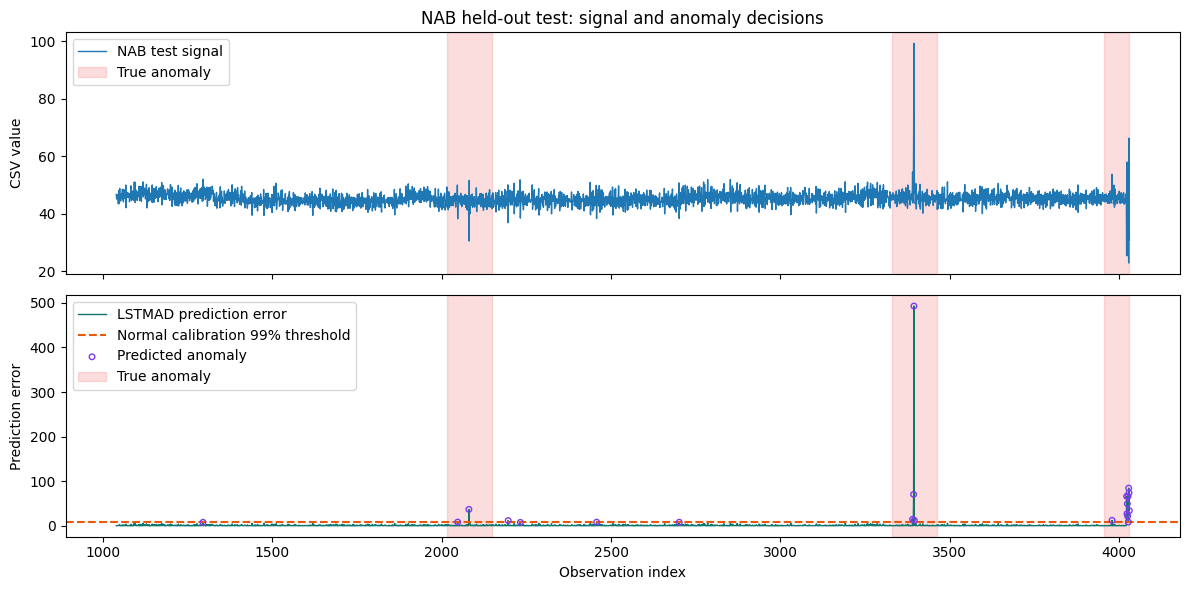

In [14]:
x = np.arange(NORMAL_END + WINDOW_SIZE, len(frame))
score_fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(x, test_x[WINDOW_SIZE:, 0], lw=1, label="NAB test signal")
axes[1].plot(x, valid_scores, lw=1, color="#0f766e", label="LSTMAD prediction error")
axes[1].axhline(threshold, color="#ea580c", ls="--", label="Normal calibration 99% threshold")
axes[1].scatter(x[pred == 1], valid_scores[pred == 1], s=16, facecolors="none",
                edgecolors="#7c3aed", label="Predicted anomaly", zorder=3)
for ax in axes:
    ax.fill_between(x, 0, 1, where=valid_y == 1, transform=ax.get_xaxis_transform(),
                    color="#ef4444", alpha=0.18, label="True anomaly")
    ax.legend(loc="upper left")
axes[0].set(title="NAB held-out test: signal and anomaly decisions", ylabel="CSV value")
axes[1].set(xlabel="Observation index", ylabel="Prediction error")
score_fig.tight_layout()
plt.show()

- 위 그림은 시험 관측값, 아래 그림은 같은 시점의 표준화된 예측오차임
- 주황 점선은 정상 보정 구간에서 고정한 임계값이며, 보라 원은 이상이라고 예측한 시점임
- 붉은 정답 구간 안에 보라 원이 없으면 놓친 이상(FN), 밖에 원이 있으면 오경보(FP)임
- 큰 변화는 잡아도 이상 구간 전체의 점수가 계속 높지 않을 수 있음.

### Step 14: 점수·평가표·시각화 저장

In [15]:
output_dir = LAB_DIR / "results/00_tsb_ad_basic"
output_dir.mkdir(parents=True, exist_ok=True)
result = frame.iloc[NORMAL_END + WINDOW_SIZE:].copy()
result.insert(0, "observation", x)
result["anomaly_score"], result["predicted_anomaly"] = valid_scores, pred
result["threshold"] = threshold
result.to_csv(output_dir / "NAB_LSTMAD_scores.csv", index=False)
metrics.to_csv(output_dir / "NAB_LSTMAD_metrics.csv", index=False)
event_table.to_csv(output_dir / "NAB_LSTMAD_events.csv", index=False)
nab_summary = {"source_commit": NAB_SHA, "profile": "standard", "scope": "single TSB example / held-out test",
               "window_source": "TSB CSV Label runs", "windows_inclusive": windows,
               "probation_percent": 0, "model_threshold": threshold, "binary_cutoff": 1.0,
               "raw_scores": raw_scores, "normalized_score": nab_score}
(output_dir / "NAB_LSTMAD_nab_score.json").write_text(
    json.dumps(nab_summary, ensure_ascii=False, indent=2), encoding="utf-8")
for figure, name in [(raw_fig, "NAB_raw_samples.png"), (sample_fig, "NAB_preprocessed_sample.png"),
                     (score_fig, "NAB_LSTMAD_plot.png")]:
    figure.savefig(output_dir / name, dpi=150, bbox_inches="tight")
print("Saved to:", output_dir)

Saved to: /home/chohi/PythonProjectLLM/AI_EDU/13w/results/00_tsb_ad_basic


- `NAB_LSTMAD_scores.csv`: 관측 번호·센서·정답·점수·이진 예측·고정 임계값을 저장
- `NAB_LSTMAD_metrics.csv`: LSTMAD와 항상 정상 기준선의 네 지표를 저장
- PNG 세 개는 원본 대표 파형, 전처리 후 샘플, 시험 평가 그래프임
- `NAB_LSTMAD_events.csv`, `NAB_LSTMAD_nab_score.json`: 구간별 탐지 결과와 NAB 평가 설정·점수를 저장

## 6) 결론

- **데이터 형상 확인 → 시간순 분할 → 전처리 샘플 확인 → LSTMAD 학습 → 정상 보정 임계값 설정 →
정확도·F1-Score·AUROC·NAB Score 평가와 해석**을 실행함
- 모델 사용의 핵심은 `LSTMAD(...)`, `fit()`, `decision_function()`
- 정확도가 높더라도 시점별 이상 분류와 구간별 이벤트 탐지는 다른 관점임. F1·AUROC와 NAB Score를 함께 확인하여 결과를 해석함

**확인 질문**

- 원본 `(644, 1)`이 왜 입력 `(612, 32, 1)`과 표적 `(612, 1, 1)`로 바뀌는가?
- 항상 정상 기준선의 정확도가 높은데도 이상감지 모델로 유용하지 않은 이유는 무엇인가?
- 임계값을 높이면 F1·AUROC·NAB Score에는 각각 어떤 영향이 있는가?
- 같은 결과에서 시점별 F1은 낮고 NAB Score는 높게 나타나는 이유는 무엇인가?

**출처와 이용 조건**

- [TSB-AD 공식 저장소](https://github.com/TheDatumOrg/TSB-AD) · [LSTMAD 구현](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/TSB_AD/models/LSTMAD.py) · [공식 ForecastDataset](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/TSB_AD/utils/dataset.py).
- [TSB-AD의 NAB 예제](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv) · [NAB 원본 시계열](https://github.com/numenta/NAB/blob/master/data/realKnownCause/ec2_request_latency_system_failure.csv) · [NAB 데이터 설명](https://github.com/numenta/NAB/blob/master/data/README.md).
- [정확도](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.accuracy_score.html) · [F1-Score](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.f1_score.html) · [AUROC](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.roc_auc_score.html)의 공식 정의를 참고
- TSB-AD 코드의 [Apache-2.0](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/LICENSE), NAB 원저장소의 [MIT 라이선스](https://github.com/numenta/NAB/blob/master/LICENSE.txt)를 확인
- [NAB 공식 채점 코드](https://github.com/numenta/NAB/blob/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/nab/sweeper.py) · [Standard 비용 설정](https://github.com/numenta/NAB/blob/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/config/profiles.json) · [NAB 평가 논문](https://arxiv.org/abs/1510.03336)을 참고